In [1]:
import os
import argparse
import torch
import torchvision
import torchvision.transforms as  transforms

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch import Tensor
from typing import Type

import matplotlib.pyplot as plt
import numpy as np

In [1]:
!nvidia-smi

Tue Nov 17 10:53:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/data
!tar -xzf /content/drive/MyDrive/HW3/cifar-10-python.tar.gz -C /content/data

Mounted at /content/drive


# Model and Data

In [3]:
#Resnet
class BasicBlock(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        expansion: int = 1,
        downsample: nn.Module = None
    ) -> None:
        super(BasicBlock, self).__init__()
        # Multiplicative factor for the subsequent conv2d layer's output channels.
        # It is 1 for ResNet18 and ResNet34.
        self.expansion = expansion
        self.downsample = downsample
        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels*self.expansion,
            kernel_size=3,
            padding=1,
            bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels*self.expansion)
    def forward(self, x):
        identity = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None:
            identity = self.downsample(x)
        out += identity
        out = self.relu(out)
        return  out


class ResNet(nn.Module):
    def __init__(
        self,
        img_channels: int,
        num_layers: int,
        block,
        num_classes: int
    ) -> None:
        super(ResNet, self).__init__()
        if num_layers == 18:
            # The following `layers` list defines the number of `BasicBlock`
            # to use to build the network and how many basic blocks to stack
            # together.
            layers = [2, 2, 2, 2]
            self.expansion = 1
        elif num_layers == 34:
            layers = [3, 4, 6, 3]
            self.expansion = 1
        elif num_layers == 50:
            layers = [3, 4, 6, 3]
            self.expansion = 4
        elif num_layers == 101:
            layers = [3, 4, 23, 3]
            self.expansion = 4

        self.in_channels = 64
        # All ResNets (18 to 152) contain a Conv2d => BN => ReLU for the first
        # three layers. Here, kernel size is 7.
        self.conv1 = nn.Conv2d(
            in_channels=img_channels,
            out_channels=self.in_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )
        self.bn1 = nn.BatchNorm2d(self.in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.Identity()
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512*self.expansion, num_classes)
    def _make_layer(
        self,
        block: Type[BasicBlock],
        out_channels: int,
        blocks: int,
        stride: int = 1
    ) -> nn.Sequential:
        downsample = None
        if stride != 1 or self.in_channels != out_channels * self.expansion:
            """
            This should pass from `layer2` to `layer4` or
            when building ResNets50 and above. Section 3.3 of the paper
            Deep Residual Learning for Image Recognition
            (https://arxiv.org/pdf/1512.03385v1.pdf).
            """
            downsample = nn.Sequential(
                nn.Conv2d(
                    self.in_channels,
                    out_channels*self.expansion,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels * self.expansion),
            )
        layers = []
        layers.append(
            block(
                self.in_channels, out_channels, stride, self.expansion, downsample
            )
        )
        self.in_channels = out_channels * self.expansion
        for i in range(1, blocks):
            layers.append(block(
                self.in_channels,
                out_channels,
                expansion=self.expansion
            ))
        return nn.Sequential(*layers)
    def forward(self, x: Tensor) -> Tensor:
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        # The spatial dimension of the final layer's feature
        # map should be (7, 7) for all ResNets.
        #print('Dimensions of the last convolutional feature map: ', x.shape)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)
        return x

In [4]:
# data
transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(0.4914, 0.4822, 0.4465),
            std=(0.2470, 0.2435, 0.2616),
        ),
    ])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=False, transform=transform)

# model
model = ResNet(img_channels=3, num_layers=18, block=BasicBlock, num_classes=10)
model.train()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(

# Training ResNet-18 on CIFAR-10 below

In [5]:
from torch.utils.data import DataLoader

trainloader = DataLoader(
    trainset,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

images, labels = next(iter(trainloader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Batches:", len(trainloader))

Images: torch.Size([128, 3, 32, 32])
Labels: torch.Size([128])
Batches: 391


# Prepare for experiments

In [6]:
# Experiment settings
SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 50
TARGET_ACC = 99.0
LR = 0.01

# Reproducibility
torch.manual_seed(SEED)

# Select CPU or GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Prepare training data
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

# Initialize a fresh ResNet-18
model = ResNet(
    img_channels=3,
    num_layers=18,
    block=BasicBlock,
    num_classes=10
).to(device)

# Loss function and baseline optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LR)

Device: cuda


# Train one epoch

In [7]:
import time

def train_one_epoch(model, optimizer, trainloader, criterion, device):
    model.train()
    total_loss = 0
    total_samples = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    for images, labels in trainloader:
        # Move data to CPU/GPU
        images = images.to(device)
        labels = labels.to(device)

        # SGD iteration
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # Accumulate loss
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    avg_loss = total_loss / total_samples

    return avg_loss, elapsed

# Evaluate Accuracy

In [8]:
@torch.no_grad()
def evaluate_accuracy(model, trainloader, device):
    model.eval()

    correct = 0
    total = 0

    for images, labels in trainloader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Predicted classes
        predictions = outputs.argmax(dim=1)

        # Count correct predictions
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    accuracy = 100 * correct / total

    return accuracy

# Run experiment

In [9]:
def run_experiment(model, optimizer, trainloader, criterion, device,
                   max_epochs=50, target_acc=99.0, scheduler=None):

    history = []
    start = time.perf_counter()
    reached = False

    for epoch in range(1, max_epochs + 1):

        # 1. Train for one epoch
        loss, train_time = train_one_epoch(
            model, optimizer, trainloader, criterion, device
        )

        # 2. Evaluate accuracy on the full training set
        accuracy = evaluate_accuracy(model, trainloader, device)

        # 3. Measure elapsed time
        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        # 4. Save results
        history.append({
            "epoch": epoch,
            "loss": loss,
            "accuracy": accuracy,
            "time": elapsed
        })

        print(
            f"Epoch {epoch:2d} | "
            f"Loss: {loss:.4f} | "
            f"Accuracy: {accuracy:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

        # 5. Stop when accuracy exceeds 99%
        if accuracy > target_acc:
            reached = True
            print(f"Target reached in {elapsed:.1f} seconds!")
            break

        # Optional learning rate scheduler
        if scheduler is not None:
            scheduler.step()

    if not reached:
        print("Target was not reached.")

    return history

In [10]:
def setup_experiment(name):
    # Same initial weights for every experiment
    torch.manual_seed(SEED)

    # Fresh ResNet-18
    model = ResNet(
        img_channels=3,
        num_layers=18,
        block=BasicBlock,
        num_classes=10
    ).to(device)

    # Same initial shuffle order
    generator = torch.Generator().manual_seed(SEED)

    loader = torch.utils.data.DataLoader(
        trainset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        generator=generator
    )

    # Choose optimizer
    if name == "SGD":
        optimizer = optim.SGD(model.parameters(), lr=0.01)

    elif name == "Momentum":
        optimizer = optim.SGD(
            model.parameters(), lr=0.01, momentum=0.9
        )

    elif name == "Nesterov":
        optimizer = optim.SGD(
            model.parameters(), lr=0.01,
            momentum=0.9, nesterov=True
        )

    elif name == "Adam":
        optimizer = optim.Adam(model.parameters(), lr=0.001)

    else:
        raise ValueError("Unknown optimizer")

    return model, optimizer, loader

# Run_All

In [11]:
import json
import gc

# Optimizers to compare
#RUN_NAMES = ["SGD", "Momentum", "Nesterov", "Adam"]
RUN_NAMES = ["Momentum", "Nesterov", "Adam"]
# Store experiment results
results = {}

# Make sure we use GPU
assert device.type == "cuda", "Enable GPU in Google Colab first!"

for name in RUN_NAMES:
    print(f"\n{'=' * 40}")
    print(f"Starting experiment: {name}")
    print(f"{'=' * 40}")

    # Fresh model and optimizer
    model, optimizer, loader = setup_experiment(name)

    # Train until 99% accuracy or MAX_EPOCHS
    history = run_experiment(
        model,
        optimizer,
        loader,
        criterion,
        device,
        max_epochs=MAX_EPOCHS,
        target_acc=TARGET_ACC
    )

    # Save results
    results[name] = history

    with open(f"results_{name}.json", "w") as f:
        json.dump(history, f, indent=2)

    # Free GPU memory
    del model, optimizer, loader
    gc.collect()
    torch.cuda.empty_cache()

print("\nAll experiments completed!")


Starting experiment: Momentum


KeyboardInterrupt: 

In [17]:
import json
from pathlib import Path

folder = Path("/content/drive/MyDrive/HW3")

# Load SGD history
with open(folder / "results_SGD.json", "r") as f:
    sgd_history = json.load(f)

# Load other optimizer histories
with open(folder / "results_recovered_all.json", "r") as f:
    other_results = json.load(f)

# Merge everything into one dictionary
results = {"SGD": sgd_history, **other_results}

# Check
for name, history in results.items():
    print(
        f"{name}: {len(history)} epochs, "
        f"accuracy={history[-1]['accuracy']:.2f}%, "
        f"time={history[-1]['time']:.1f}s"
    )

SGD: 9 epochs, accuracy=99.97%, time=594.9s
Momentum: 10 epochs, accuracy=99.02%, time=768.2s
Nesterov: 11 epochs, accuracy=99.66%, time=849.5s
Adam: 18 epochs, accuracy=99.08%, time=1395.2s


In [18]:
with open(folder / "results_all.json", "w") as f:
    json.dump(results, f, indent=2)

# Results

In [14]:
import matplotlib.pyplot as plt

def plot_results(results):
    # Accuracy vs Time
    plt.figure(figsize=(9, 5))

    for name, history in results.items():
        times = [h["time"] for h in history]
        accuracies = [h["accuracy"] for h in history]

        plt.plot(times, accuracies, marker="o", label=name)

    plt.axhline(y=99, color="red", linestyle="--", label="Target: 99%")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Training Accuracy (%)")
    plt.title("Training Accuracy vs Time")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Loss vs Time
    plt.figure(figsize=(9, 5))

    for name, history in results.items():
        times = [h["time"] for h in history]
        losses = [h["loss"] for h in history]

        plt.plot(times, losses, marker="o", label=name)

    plt.xlabel("Time (seconds)")
    plt.ylabel("Training Loss")
    plt.title("Training Loss vs Time")
    plt.legend()
    plt.grid(True)
    plt.show()

In [15]:
def compare_results(results):
    times_to_target = {}

    for name, history in results.items():
        reached = next(
            (h for h in history if h["accuracy"] > TARGET_ACC),
            None
        )

        times_to_target[name] = (
            reached["time"] if reached is not None else None
        )

    baseline = times_to_target.get("SGD")

    print(f"{'Optimizer':<15} {'Time to 99%':<18} {'Speedup'}")
    print("-" * 45)

    for name, t in times_to_target.items():
        if t is None:
            print(f"{name:<15} {'Not reached':<18} N/A")
        else:
            speedup = baseline / t if baseline is not None else None
            speedup_text = f"{speedup:.2f}x" if speedup else "N/A"

            print(f"{name:<15} {t:<18.1f} {speedup_text}")

    return times_to_target

# Cosine annealing

In [16]:
def run_cosine_experiment():
    # Fresh model with the same initial weights as SGD
    model, optimizer, loader = setup_experiment("SGD")

    # Learning rate scheduler
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_EPOCHS,
        eta_min=0.0001
    )

    # Run experiment
    history = run_experiment(
        model,
        optimizer,
        loader,
        criterion,
        device,
        max_epochs=MAX_EPOCHS,
        target_acc=TARGET_ACC,
        scheduler=scheduler
    )

    # Save results
    with open("results_SGD_Cosine.json", "w") as f:
        json.dump(history, f, indent=2)

    return history

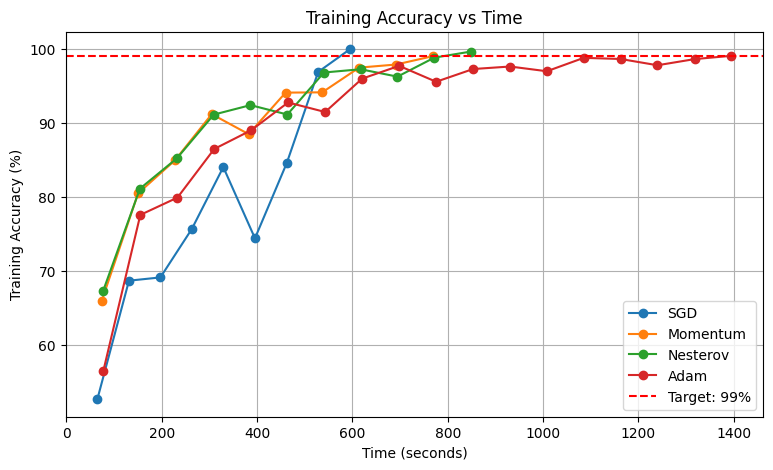

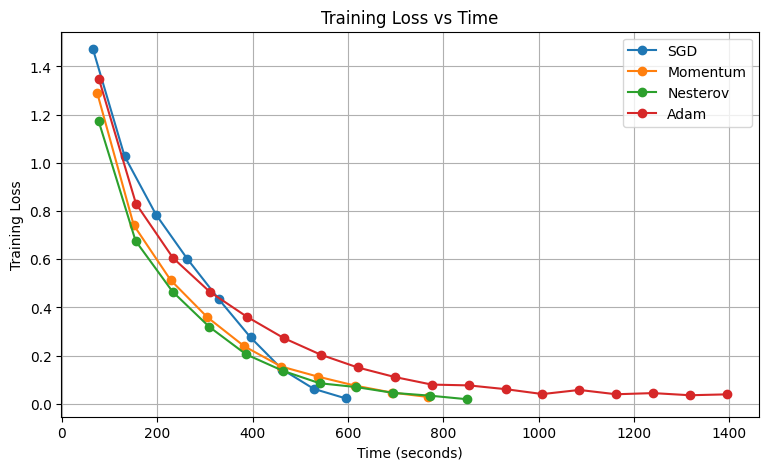

In [19]:
plot_results(results)

In [20]:
compare_results(results)

Optimizer       Time to 99%        Speedup
---------------------------------------------
SGD             594.9              1.00x
Momentum        768.2              0.77x
Nesterov        849.5              0.70x
Adam            1395.2             0.43x


{'SGD': 594.8908240149999,
 'Momentum': 768.2,
 'Nesterov': 849.5,
 'Adam': 1395.2}

## Discussion & Conclusion

### Discussion
- All four optimizers achieved the target training accuracy of 99%.
- SGD reached 99% accuracy fastest (594.9 seconds).
- Momentum and Nesterov required more training time.
- Adam was the slowest under the selected hyperparameters.
- Results depend on learning rates, optimizer settings, and model architecture.

### Conclusion
Vanilla SGD achieved the best time-to-target performance
in this experiment. However, these results do not imply
that SGD is universally superior to adaptive optimizers.